In [3]:
import re
from collections import Counter
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

import nltk
from nltk.corpus import nps_chat

import src.dialogueClassifier as dc
import matplotlib.pyplot as plt

Accuracy: 0.5999055266887104
Balanced accuracy: 0.43188597682379154
Macro F1: 0.41031828564433004
              precision    recall  f1-score   support

      Accept       0.58      0.25      0.34        61
         Bye       0.80      0.80      0.80        25
     Clarify       0.00      0.17      0.01         6
   Continuer       0.31      0.07      0.12        54
     Emotion       0.97      0.57      0.72       185
    Emphasis       0.08      0.09      0.08        46
       Greet       0.70      0.84      0.77       207
       Other       0.00      0.00      0.00         6
      Reject       0.22      0.24      0.23        41
   Statement       0.57      0.51      0.54       644
      System       0.99      0.79      0.88       593
     nAnswer       0.09      0.42      0.15        12
  whQuestion       0.69      0.70      0.69       119
     yAnswer       0.28      0.62      0.38        13
  ynQuestion       0.45      0.42      0.44       105

    accuracy                        

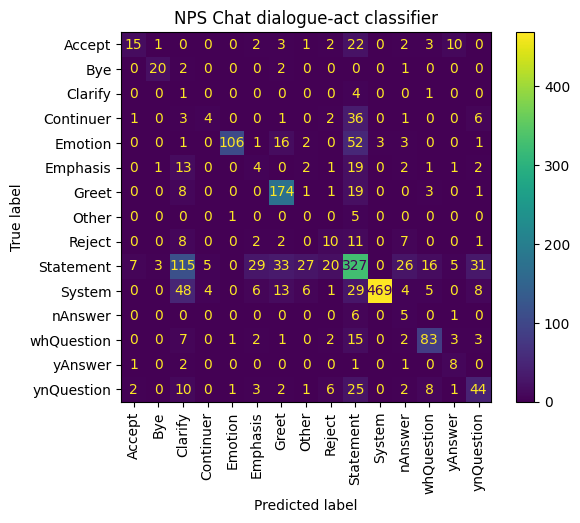

In [ ]:
# co-pilot utilization done for result visualization

# Split by NPS Chat session rather than individual posts to prevent session leakage.
fileIds = nps_chat.fileids()
train, test = train_test_split(fileIds, test_size=0.2, random_state=42)

trainExamples = dc.ExamplesFromFiles(train)
testExamples = dc.ExamplesFromFiles(test)

# Evaluate on held-out conversations before fitting the deployable all-data model.
evalVocabularry, evalClassifier = dc.TrainClassifier(trainExamples)

y_test = []
testFeatures = []
for text, label in testExamples:
    y_test.append(label)
    testFeatures.append(dc.DialogueActFeatures(text, evalVocabularry))

y_pred = evalClassifier.classify_many(testFeatures)

actNames = set()
for _, label in trainExamples + testExamples:
    actNames.add(label)
actNames = sorted(actNames)


# Output results
print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred)}")
print(f"Macro F1: {f1_score(y_test, y_pred, average='macro', zero_division=0)}")
print(classification_report(y_test, y_pred, labels=actNames, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=actNames, xticks_rotation='vertical')
plt.title("NPS Chat dialogue-act classifier")
plt.show()


In [5]:
#nps chat classifier test
# Train the reusable model on all NPS Chat utterances and labels.
examples = dc.ExamplesFromFiles(fileIds)
dialogueActVocabulary, dialogueActClassifier = dc.TrainClassifier(examples)

# Example application: predictions aligned with task 0's NPS Chat posts.
npsTexts = []
for text, _ in examples:
    npsTexts.append(text)

predictedLabels = dc.PredictDialogueActs(npsTexts, dialogueActVocabulary, dialogueActClassifier)
textDict = dict(zip(predictedLabels, npsTexts))
print(f"Trained on {len(examples)} NPS Chat utterances across {len(actNames)} dialogue acts.")
print(textDict)


Trained on 10567 NPS Chat utterances across 15 dialogue acts.
{'Statement': 'Uh.', 'System': 'JOIN', 'Greet': 'Hi, 11-09-teensUser197.', 'Clarify': 'Were you on one of the nicks i kicked out 11-09-teensUser34? lol', 'nAnswer': 'Not that I know of, 11-09-teensUser98', 'Emphasis': 'oh 11-09-teensUser122 im mad at you', 'Reject': 'No myspace talk.', 'whQuestion': 'how are you ppl?', 'Other': 'Heyyy. :) <33.', 'Continuer': 'In da butt. :O', 'ynQuestion': 'any fine gurls in hurr pm me to find me out', 'Emotion': 'lmao', 'Accept': '11-09-teensUser57.', 'yAnswer': 'well it is evil', 'Bye': 'brb'}
